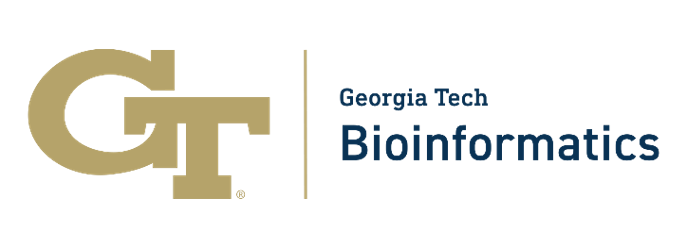

<div class="alert alert-block alert-info">
    <h1>BIOL 4150/BIOL 6150</h1>
    <h3>Instructor: Dr. King Jordan</h3>
    <p>Nilavrah Sensarma (nsensarma3@gatech.edu)</p>
    <p>Valli Sree Lasya Pasumarthy (vpasumarthy3@gatech.edu)

</p>
</div>

<div class="alert alert-block alert-warning">
    <h2>Project 6 (GWAS on UK Biobank) starter notebook</h2>
    <h3>Deadline: 11:59PM, November 3rd, 2025</h3>
</div>

### Rerun the GWAS for the whole genome (c1-22)


<div class="alert alert-block alert-warning">
    <h2>Part 1 - Preprocessing</h2>
    <h2> Total Points: 2+5+5 = 12</h2>
</div>

In [1]:
#List the genotypes, phenotype and covariates files


In [2]:
!mkdir -p ~/scratch/gwas/

In [2]:
#Check that the files are available
!ls -lh ~/biol6150/Data2/GWAS/


!unzip ~/biol6150/Data2/GWAS/genotypes.zip -d ~/scratch/gwas/

total 16G
-rw-r-----. 1 ylyu82     gtperson          691M Oct 30 13:06 c16.bed
-rw-r-----. 1 ylyu82     gtperson          819K Oct 30 13:06 c16.bim
-rw-r-----. 1 ylyu82     gtperson          2.4M Oct 30 13:06 c16.fam
-rw-rw-r--. 1 nsensarma3 bios-pace-ice-tas 9.8M Oct 23  2025 covars.tsv
-rw-rw-r--. 1 nsensarma3 bios-pace-ice-tas  15G Oct 23  2025 genotypes.zip
-rw-rw-r--. 1 nsensarma3 bios-pace-ice-tas 1.8M Oct 23  2025 phe.tsv
Archive:  /home/hice1/cechcharef3/biol6150/Data2/GWAS/genotypes.zip
   creating: /home/hice1/cechcharef3/scratch/gwas/genotypes_100k/
  inflating: /home/hice1/cechcharef3/scratch/gwas/genotypes_100k/c1.log  
  inflating: /home/hice1/cechcharef3/scratch/gwas/genotypes_100k/c2.log  
  inflating: /home/hice1/cechcharef3/scratch/gwas/genotypes_100k/c3.log  
  inflating: /home/hice1/cechcharef3/scratch/gwas/genotypes_100k/c4.log  
  inflating: /home/hice1/cechcharef3/scratch/gwas/genotypes_100k/c5.log  
  inflating: /home/hice1/cechcharef3/scratch/gwas/genotypes_100

In [3]:
!ls -lh ~/scratch/gwas/genotypes_100k/

total 37G
-rw-rw----. 1 cechcharef3 gtperson  914M Oct 23  2025 c10.bed
-rw-rw----. 1 cechcharef3 gtperson  914M Oct 23  2025 c10.bed~
-rw-rw----. 1 cechcharef3 gtperson  1.1M Oct 23  2025 c10.bim
-rw-rw----. 1 cechcharef3 gtperson  1.1M Oct 23  2025 c10.bim~
-rw-rw----. 1 cechcharef3 gtperson  2.4M Oct 23  2025 c10.fam
-rw-rw----. 1 cechcharef3 gtperson  2.4M Oct 23  2025 c10.fam~
-rw-rw----. 1 cechcharef3 gtperson   951 Oct 23  2025 c10.log
-rw-rw----. 1 cechcharef3 gtperson  974M Oct 23  2025 c11.bed
-rw-rw----. 1 cechcharef3 gtperson  974M Oct 23  2025 c11.bed~
-rw-rw----. 1 cechcharef3 gtperson  1.2M Oct 23  2025 c11.bim
-rw-rw----. 1 cechcharef3 gtperson  1.2M Oct 23  2025 c11.bim~
-rw-rw----. 1 cechcharef3 gtperson  2.4M Oct 23  2025 c11.fam
-rw-rw----. 1 cechcharef3 gtperson  2.4M Oct 23  2025 c11.fam~
-rw-rw----. 1 cechcharef3 gtperson   951 Oct 23  2025 c11.log
-rw-rw----. 1 cechcharef3 gtperson  890M Oct 23  2025 c12.bed
-rw-rw----. 1 cechcharef3 gtperson  890M Oct 23  2025 

In [4]:
!cp ~/biol6150/Data2/GWAS/covars.tsv  ~/scratch/gwas/
!cp ~/biol6150/Data2/GWAS/phe.tsv ~/scratch/gwas/

In [5]:

!head ~/scratch/gwas/covars.tsv

print("-----------------------------")

!head ~/scratch/gwas/phe.tsv

FID	IID	Age	Sex	PC1	PC2	PC3	PC4	PC5	PC6	PC7	PC8	PC9
P000001	P000001	66	Female	-9.46068	3.99329	-2.52249	1.38471	-3.40503	-0.345494	1.44075	-0.304621	-5.63078
P000002	P000002	60	Male	-12.9698	5.05658	-0.380204	-0.257499	-6.38521	0.782127	1.18262	-1.20464	-1.79521
P000003	P000003	54	Male	-12.5417	2.72269	-0.875929	-0.737377	-7.69949	0.488432	1.953	-0.403165	0.602469
P000004	P000004	64	Male	-10.5744	4.00753	-0.662397	0.765802	-6.79584	2.60056	0.183747	1.27873	3.43894
P000005	P000005	46	Male	-10.248	5.84242	-3.19615	4.83306	20.3532	-3.79915	1.87694	-0.368646	1.49299
P000006	P000006	65	Male	-8.56442	6.72697	-1.46162	-3.63724	-0.904876	1.82036	3.39045	-2.82143	3.30762
P000007	P000007	48	Female	-11.4792	2.10319	1.08804	-1.70238	-8.98411	3.01852	2.22325	0.458742	2.49605
P000008	P000008	56	Male	82.3299	-36.1549	24.0605	-14.9267	2.89455	15.3657	8.93768	0.0721649	-3.40696
P000009	P000009	57	Male	-15.4749	4.17825	-4.07577	6.18505	-6.18584	0.338571	1.76484	-2.29568	-3.15414
------------------------

<div class="alert alert-block alert-warning">
    <h4> 1.1 Why do we have FID and IID in the files? Would they be different? If so, when?</h4>
</div>


FID is the family ID and IID is the individual ID. This is the PLINK convention, where the pair (FID, IID) uniquely identifies a sample.
Together they are the key PLINK uses to match people across the .fam file, the phenotype file (phe.tsv) and the covariate file (covars.tsv).

In family-based data, FID groups relatives (parents, siblings), and IID is unique within the family. Two people can share an FID but have different IIDs. IID alone may not be unique across families, which is why we need both
In population cohorts like UK Biobank, everyone is treated as unrelated. FID is set equal to IID, or sometimes to 0, so the two columns are identical.
Relatedness still matters in practice. UKB has many relatives, so people often filter by kinship or use mixed models (REGENIE, SAIGE, BOLT-LMM). 

<div class="alert alert-block alert-warning">
    <h4> 1.2 How would you extract the Sample IDs if the genotypes weren't in plink bed/bim/fam format? Give examples</h4>
</div>


In bed/bim/fam, the sample IDs are columns 1 and 2 of the .fam file. For other formats, the IDs are stored in different places:

- VCF/BCF: the sample names are in the #CHROM header line.
    `bcftools query -l cohort.vcf.gz > samples.txt`
- PLINK 2 (pgen/pvar/psam): the IDs are in the .psam file.
    `cut -f1,2 cohort.psam`
- BGEN: the IDs are in the accompanying .sample file (columns ID_1 and ID_2), or embedded in the BGEN and exportable with qctool.
    `qctool -g cohort.bgen -os samples.sample`
- PLINK text format (ped/map): the IDs are columns 1 and 2 of the .ped file.
    `cut -d' ' -f1,2 cohort.ped`

If a format only has a single ID column like in VCF, we can do FID = IID so the IDs can be used with PLINK flags like --keep and --pheno:
    `awk '{print $1, $1}' samples.txt > keep_ids.txt`

<div class="alert alert-block alert-warning">
    <h4> 1.3 We're using PCs 1-9 for covariates. Would it be different if we used, say, PCs 1-5? How so?</h4>
</div>


Yes, the results would differ. PCs are included as covariates to capture population structure (ancestry differences) so that it does not confound the association between genotype and phenotype. Each PC captures a different axis of genetic variation, with the top PCs explaining the most.

- With PCs 1-5, the major ancestry axes are still controlled, but the finer structure captured by PCs 6-9 is left uncorrected. This can leave some residual confounding, which shows up as slightly higher genomic inflation (λGC > 1), a lifted Q-Q plot, and possibly a few false-positive associations.
- With PCs 1-9, more of the subtle structure is accounted for, so λGC is usually closer to 1 and p-values are better calibrated. The downside is that each extra covariate uses a degree of freedom, and if the added PCs carry little real structure, there is a small loss of power. With a large sample this loss is minor.

The strongest associations stay stable, but p-values and effect sizes shift slightly, and borderline hits near the significance threshold may appear or disappear. The number of PCs is typically chosen by looking at how variance explained levels off (scree plot) and by comparing λGC / Q-Q plots across different numbers of PCs.

<div class="alert alert-block alert-warning">
    <h2>Part 2 - Running GWAS</h2>
    <h2> Total Points: 10+6+6=22</h2>
</div>

<div class="alert alert-block alert-warning">
    <h4>2.1 Run the GWAS using plink</h4>
</div>


In [11]:
%%bash
mkdir -p ~/scratch/gwas/gwas_results

for chr in {1..22}; do
  plink2 \
    --bfile ~/scratch/gwas/genotypes_100k/c${chr} \
    --pheno ~/scratch/gwas/phe.tsv \
    --pheno-name T2D \
    --covar ~/scratch/gwas/covars.tsv \
    --covar-name Age,Sex,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9 \
    --glm hide-covar firth-fallback cols=+a1freq,+orbeta \
    --no-input-missing-phenotype \
    --geno 0.02 --maf 0.01 \
    --threads 8 \
    --out ~/scratch/gwas/gwas_results/c${chr}
done

ls ~/scratch/gwas/gwas_results/

PLINK v2.00a5LM 64-bit Intel (23 Sep 2023)     www.cog-genomics.org/plink/2.0/
(C) 2005-2023 Shaun Purcell, Christopher Chang   GNU General Public License v3
Logging to /home/hice1/cechcharef3/scratch/gwas/gwas_results/c1.log.
Options in effect:
  --bfile /home/hice1/cechcharef3/scratch/gwas/genotypes_100k/c1
  --covar /home/hice1/cechcharef3/scratch/gwas/covars.tsv
  --covar-name Age,Sex,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
  --geno 0.02
  --glm hide-covar firth-fallback cols=+a1freq,+orbeta
  --maf 0.01
  --no-input-missing-phenotype
  --out /home/hice1/cechcharef3/scratch/gwas/gwas_results/c1
  --pheno /home/hice1/cechcharef3/scratch/gwas/phe.tsv
  --pheno-name T2D
  --threads 8

Start time: Fri Nov  6 00:20:46 2026
515314 MiB RAM detected, ~496649 available; reserving 257657 MiB for main
workspace.
Using up to 8 compute threads.
100000 samples (54417 females, 45550 males, 33 ambiguous; 100000 founders)
loaded from /home/hice1/cechcharef3/scratch/gwas/genotypes_100k/c1.fam.
63487 var

<div class="alert alert-block alert-warning">
    <h4>2.2 What flags did you use for performing the GWAS? What do they mean? Why and how did you choose the values you chose?</h4>
</div>


Command is run per chromosome c{chr}

- --bfile: input genotypes in PLINK binary format (.bed/.bim/.fam). 

- --pheno / --pheno-name T2D: the phenotype file and the column to test. T2D is binary (case/control), so PLINK runs logistic regression.

- --covar / --covar-name: the covariate file and the covariates to adjust for. We used Age, Sex and PC1-PC9. The PCs capture population structure so ancestry differences don't create false associations.

- --glm: runs the per-variant association regression (logistic for a binary trait).
  - hide-covar: only writes the result row for the tested variant, not for every covariate. This keeps output files small, since we only care about the genotype effect.
  - firth-fallback: uses standard logistic regression, but switches to Firth penalized regression when it fails to converge or there is (quasi-)complete separation. This is important for rarer variants, where few minor-allele carriers among cases can make ordinary logistic regression unreliable.
  - cols=+a1freq,+orbeta: adds the A1 allele frequency column and the odds ratio / beta effect-size column to the output.

- --no-input-missing-phenotype: tells PLINK not to treat numeric codes like -9 or 0 in the phenotype file as missing, so the 0/1 case-control coding is read as given (missing values are NA). The log confirms the result: 7,758 cases and 91,573 controls.

- --geno 0.02: removes variants missing in more than 2% of samples. Variants with high missingness have unreliable genotype calls and can cause artefactual associations. 2% is a standard, fairly strict cutoff (0.02 removed 7,474 variants on chr1).

- --maf 0.01: removes variants with minor allele frequency below 1%. Rare variants have too few carriers for stable effect estimates and are underpowered in a single-variant test, and they are more prone to false positives. 1% is the usual common-variant GWAS cutoff (removed 9,540 on chr1).

- --threads 8: uses 8 CPU threads to speed up computation.

- --out: prefix for the output files.

<div class="alert alert-block alert-warning">
    <h4>2.3 What is the difference between beta(β) and log(OR) in the outputs? When do you expect them to coincide?</h4>
</div>



- β (beta) is the coefficient from linear regression for a quantitative trait. It is the change in the trait per additional copy of the effect allele.
- log(OR) is the coefficient from logistic regression for a binary trait (e.g. T2D case/control). It is the change in the log-odds of being a case per additional copy of the effect allele. The odds ratio is OR = exp(β_logistic), so log(OR) = β_logistic.

In PLINK 2 logistic output, the effect column (OR) reports the odds ratio. Taking the natural log gives the log(OR), which is the logistic regression β. OR = 1 (log(OR) = 0) means no effect; OR > 1 means the allele increases risk; OR < 1 means it is protective. Because the log scale is symmetric around 0 and approximately normal, log(OR) is the quantity used with its standard error (SE) for the test statistic and for meta-analysis.

They coincide in the sense that in a logistic model the "β" IS the log(OR). Howeer, in linear-regression β on a trait is not generaly equal to a log(OR). They approximate each other. for example, when the trait is a rare binary disease, effects are small, and a linear model on 0/1 gives a β that is roughly proportional to the risk change.

<div class="alert alert-block alert-warning">
    <h2>Part 3 - Visualisation</h2>
    <h2> Total Points: 12+12+12 = 36</h2>
</div>

## **3.1 Manhattan Plot**
### *Total Questions: 3*
### *Total Points: 8+2+2 = 12*


---

<div class="alert alert-block alert-warning">
    <h4>3.1.1 Plot a Manhattan plot. Explain what it represents and how it's useful</h4>
    <p> Hint: There are packages available for Manhattan and Q-Q plots. You can try using them or writing the code from scratch. Ensure the significance line is included in any case.
</div>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

In [14]:
GWAS_DIR = Path.cwd() / "gwas_results"

files = sorted(
    GWAS_DIR.glob("c*.T2D.glm.logistic.hybrid"),
    key=lambda f: int(f.name.split(".")[0][1:])
)

assert GWAS_DIR.exists(), f"GWAS directory not found: {GWAS_DIR}"
assert len(files) == 22, f"Expected 22 files, found {len(files)}"

gwas_results = []

for file in files:
    df = pd.read_csv(file, sep="\t")
    gwas_results.append(df)

gwas_df = pd.concat(gwas_results, ignore_index=True)

CHR = pick(df, "CHR", "CHROM", "#CHROM")
BP  = pick(df, "BP", "POS")
P   = pick(df, "P", "PVALUE")

# We keep valid p-values
gwas_df = gwas_df[np.isfinite(gwas_df[P]) & (gwas_df[P] > 0)]

# Compute -log10(p)
gwas_df["LOG10P"] = -np.log10(gwas_df[P])

print("Total GWAS records:", len(gwas_df))
print("Chromosomes analyzed:", gwas_df[CHR].nunique())


gwas_df.head()

Total GWAS records: 584931
Chromosomes analyzed: 22


,#CHROM,POS,ID,REF,ALT,PROVISIONAL_REF?,A1,OMITTED,A1_FREQ,FIRTH?,TEST,OBS_CT,OR,LOG(OR)_SE,Z_STAT,P,ERRCODE,LOG10P
0,1,752721,rs3131972,G,A,Y,A,G,0.170629,N,ADD,98758,1.031320,0.023534,1.310310,0.190093,.,0.721034
1,1,754105,rs12184325,T,C,Y,T,C,0.036831,N,ADD,99209,0.980040,0.046415,-0.434378,0.664014,.,0.177823
2,1,756604,rs3131962,G,A,Y,A,G,0.139911,N,ADD,99127,1.052530,0.024407,2.097430,0.035956,.,1.444232
3,1,768448,rs12562034,A,G,Y,A,G,0.111949,N,ADD,99108,0.965118,0.026820,-1.323820,0.185562,.,0.731511
4,1,772927,rs116390263,T,C,Y,T,C,0.029786,N,ADD,99142,1.009340,0.050974,0.182366,0.855295,.,0.067884


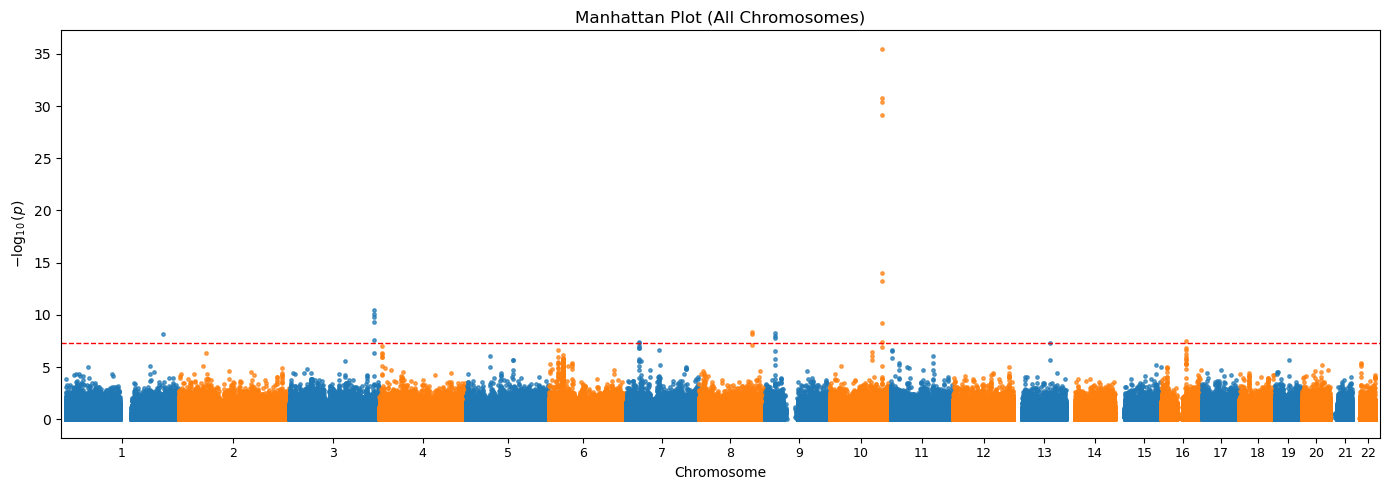

In [15]:
# Calculate cumulative genomic positions so chromosomes don't overlap
chrom_lengths = gwas_df.groupby(CHR, sort=False)[BP].max()
chrom_offsets = chrom_lengths.shift(fill_value=0).cumsum()

gwas_df['bp_offset'] = gwas_df[CHR].map(chrom_offsets)
gwas_df['plot_bp'] = gwas_df[BP] + gwas_df['bp_offset']

# Calculate tick positions at the center of each chromosome for labeling
chrom_centers = gwas_df.groupby(CHR, sort=False)['plot_bp'].mean()

# Plot the Manhattan plot with alternating colors
plt.figure(figsize=(14, 5))

colors = ['tab:blue', 'tab:orange']
for i, (chrom, group) in enumerate(gwas_df.groupby(CHR, sort=False)):
    color = colors[i % len(colors)]
    plt.scatter(group['plot_bp'], group["LOG10P"], s=6, alpha=0.7, color=color)

# Add genome-wide significance threshold line (5e-8)
plt.axhline(-np.log10(5e-8), ls="--", color="red", lw=1, label="Significance threshold")

# Customize axes and labels
plt.xticks(ticks=chrom_centers, labels=chrom_centers.index, fontsize=9)
plt.xlim(gwas_df['plot_bp'].min() - 1e7, gwas_df['plot_bp'].max() + 1e7)
plt.title("Manhattan Plot (All Chromosomes)")
plt.xlabel("Chromosome")
plt.ylabel(r"$-\log_{10}(p)$")
plt.tight_layout()
plt.show()

Above we are plotting each chromosome on a manhattan plot, showing significance across the genome.

<div class="alert alert-block alert-warning">
    <h4>3.1.2 What does each point in the plot mean? What does the dashed line represent?</h4>
</div>

Each point on the plot represents a single variant, with stacks showing higher significance. The dashed line is the significance line, where points above represent a statistically significant hit.

<div class="alert alert-block alert-warning">
    <h4>3.1.3 What does it mean if you see broad peaks across many chromosomes? Give two reasons</h4>
</div>

Those chromosomes might both influence the phenotype. This means that these traits are polygenic, which is the whole point of making a polygenic risk score.

## **3.2 Volcano Plot**
### *Total Questions: 3*
### *Total Points: 8+2+2 = 12*


---

<div class="alert alert-block alert-warning">
    <h4>3.2.1 Plot a volcano plot. Describe what it explains and how it is useful</h4>
</div>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Total GWAS records: 584931
Chromosomes analyzed: 22
Total additive variants: 584931
Genome-wide significant variants: 23


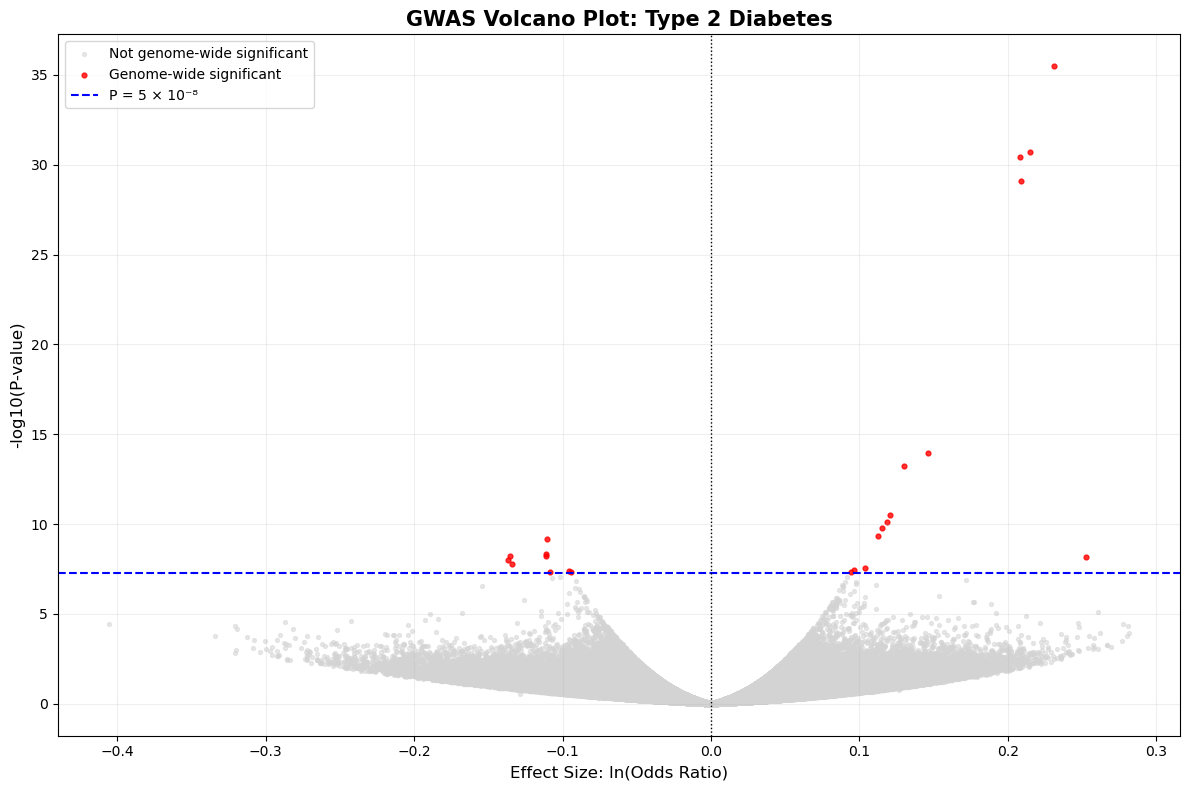

In [5]:

# --------------------------------------------------
# 1. Load and combine GWAS results from all 22 chromosomes
# --------------------------------------------------

GWAS_DIR = Path.cwd() / "gwas/gwas_results"

files = sorted(
    GWAS_DIR.glob("c*.T2D.glm.logistic.hybrid"),
    key=lambda f: int(f.name.split(".")[0][1:])
)

assert GWAS_DIR.exists(), f"GWAS directory not found: {GWAS_DIR}"
assert len(files) == 22, f"Expected 22 files, found {len(files)}"

gwas_results = []

for file in files:
    df = pd.read_csv(file, sep="\t")
    gwas_results.append(df)

gwas_df = pd.concat(gwas_results, ignore_index=True)

print("Total GWAS records:", len(gwas_df))
print("Chromosomes analyzed:", gwas_df["#CHROM"].nunique())

# --------------------------------------------------
# 2. Filter and prepare association results
# --------------------------------------------------

# Retain additive genetic association tests without errors
volcano_df = gwas_df[
    (gwas_df["TEST"] == "ADD") &
    (gwas_df["ERRCODE"].astype(str).str.strip() == ".")
].copy()

# Convert relevant columns to numeric
for column in ["P", "OR"]:
    volcano_df[column] = pd.to_numeric(
        volcano_df[column], errors="coerce"
    )

# Remove invalid values
volcano_df = volcano_df[
    volcano_df["P"].notna() &
    (volcano_df["P"] >= 0) &
    (volcano_df["P"] <= 1) &
    volcano_df["OR"].notna() &
    (volcano_df["OR"] > 0) &
    np.isfinite(volcano_df["OR"])
].copy()

# Calculate log odds ratio and -log10(p-value)
volcano_df["LOG_OR"] = np.log(volcano_df["OR"])

volcano_df["NEG_LOG10_P"] = -np.log10(
    volcano_df["P"].clip(lower=np.finfo(float).tiny)
)

# Define genome-wide significance threshold
SIGNIFICANCE_THRESHOLD = 5e-8

volcano_df["SIGNIFICANT"] = (
    volcano_df["P"] < SIGNIFICANCE_THRESHOLD
)

# Report variant counts
print("Total additive variants:", len(volcano_df))
print(
    "Genome-wide significant variants:",
    volcano_df["SIGNIFICANT"].sum()
)

# --------------------------------------------------
# 3. Generate the volcano plot
# --------------------------------------------------

plt.figure(figsize=(12, 8))

# Nonsignificant variants
nonsignificant = volcano_df[
    ~volcano_df["SIGNIFICANT"]
]

plt.scatter(
    nonsignificant["LOG_OR"],
    nonsignificant["NEG_LOG10_P"],
    color="lightgray",
    alpha=0.5,
    s=8,
    label="Not genome-wide significant"
)

# Genome-wide significant variants
significant = volcano_df[
    volcano_df["SIGNIFICANT"]
]

plt.scatter(
    significant["LOG_OR"],
    significant["NEG_LOG10_P"],
    color="red",
    alpha=0.8,
    s=12,
    label="Genome-wide significant"
)

# Genome-wide significance threshold
plt.axhline(
    -np.log10(SIGNIFICANCE_THRESHOLD),
    color="blue",
    linestyle="--",
    linewidth=1.5,
    label="P = 5 × 10⁻⁸"
)

# Reference line representing no effect
plt.axvline(
    0,
    color="black",
    linestyle=":",
    linewidth=1
)

# Labels and title
plt.xlabel("Effect Size: ln(Odds Ratio)", fontsize=12)
plt.ylabel("-log10(P-value)", fontsize=12)

plt.title(
    "GWAS Volcano Plot: Type 2 Diabetes",
    fontsize=15,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

#### Volcano Plot Description and the Use of Volcano Plots:

A volcano plot was generated to visualize the association between genetic variants and Type 2 Diabetes using GWAS results from all 22 chromosomes. Each point represents an individual genetic variant (SNP). The x-axis represents the effect size, calculated as the natural logarithm of the odds ratio (ln(OR)), while the y-axis represents statistical significance, calculated as −log10(P-value).

Furthemore, the horizontal dashed line represents the genome-wide significance threshold of P < 5 × 10⁻⁸, which accounts for the large number of statistical tests performed in a GWAS. Variants above this threshold are considered genome-wide significant, while variants below it do not meet this significance criterion. The vertical reference line at ln(OR) = 0 represents no effect. Positive values indicate increased odds of Type 2 Diabetes associated with the effect allele, whereas negative values indicate decreased odds.

The volcano plot is useful because it simultaneously displays the magnitude and direction of genetic effects and the statistical significance of associations. It allows researchers to identify potentially important genetic variants, distinguish significant associations from nonsignificant findings, and identify variants that may contribute to the genetic susceptibility of Type 2 Diabetes.

<div class="alert alert-block alert-warning">
    <h4>3.2.2 Who contributed to the novel generation of volcano plots? Which paper was it?</h4>
</div>

#### Who contributed to the novel generation of volcano plots? Which paper was it?

Xiangqin Cui and Gary A. Churchill contributed to the development and application of volcano plots in genomic research through their 2003 publication, "Statistical tests for differential expression in cDNA microarray experiments," published in Genome Biology, Volume 4, Article 210.

Moreover, the paper discussed the volcano plot as an effective graphical approach for summarizing both changes in gene expression and their corresponding statistical significance. It demonstrated how plotting log-transformed fold changes against negative log-transformed P-values can help researchers identify biologically relevant and statistically significant differences in gene expression.

Hence, their work became an important reference for the use of volcano plots in genomics and gene-expression analysis.

<div class="alert alert-block alert-warning">
    <h4>3.2.3 How many points pass the significance threshold? Is it good? If not, what could be the possible reasons? How can you improve it?</h4>
</div>

In [6]:

# --------------------------------------------------
# Count genome-wide significant variants
# --------------------------------------------------

significant_variants = volcano_df[
    volcano_df["P"] < 5e-8
].copy()

total_significant = len(significant_variants)

print("Total variants analyzed:", len(volcano_df))
print("Genome-wide significant variants:", total_significant)

print("\nSignificant variants by chromosome:")
print(
    significant_variants.groupby("#CHROM").size()
)

print("\nTop 10 most significant variants:")
display(
    significant_variants.sort_values("P")[
        ["#CHROM", "POS", "ID", "A1", "OR", "P"]
    ].head(10)
)

Total variants analyzed: 584931
Genome-wide significant variants: 23

Significant variants by chromosome:
#CHROM
1     1
3     5
7     2
8     2
9     3
10    8
13    1
16    1
dtype: int64

Top 10 most significant variants:


,#CHROM,POS,ID,A1,OR,P
357900,10,114758349,rs7903146,T,1.26012,3.285200e-36
357904,10,114788815,rs12243326,C,1.23958,1.866590e-31
357898,10,114756041,rs4506565,T,1.23171,3.863180e-31
357908,10,114808902,rs12255372,T,1.23233,7.910560e-30
357890,10,114736614,rs11196175,C,1.15752,1.042540e-14
357903,10,114781297,rs10787472,C,1.13885,5.689300e-14
128917,3,185530290,rs6769511,C,1.12818,3.296560e-11
128916,3,185529080,rs1470579,C,1.12561,7.680160e-11
128912,3,185513392,rs7651090,G,1.12246,1.620430e-10
128910,3,185511687,rs4402960,T,1.11917,4.438620e-10


#### How many points pass the significance threshold? Is it good? If not, what could be the possible reasons? How can you improve it?

A total of 23 genetic variants out of 584,931 analyzed variants passed the genome-wide significance threshold of P < 5 × 10⁻⁸ in the Type 2 Diabetes GWAS analysis.

The significant variants were distributed across chromosomes 1, 3, 7, 8, 9, 10, 13, and 16, with chromosome 10 containing the greatest number of significant associations (8 variants). The strongest association was identified on chromosome 10 at rs7903146 (position 114,758,349), which had an odds ratio of 1.26012 and a P-value of 3.2852 × 10⁻³⁶. This indicates that the effect allele, T, was associated with approximately 26% higher odds of Type 2 Diabetes compared with the alternative allele, under the additive genetic model.

Identifying 23 genome-wide significant variants is a promising result because these associations provide evidence of genetic variants associated with Type 2 Diabetes. However, the number of significant variants alone does not determine the overall quality of a GWAS. Several significant SNPs may be correlated because of linkage disequilibrium (LD), meaning that they may represent fewer independent genetic association signals. In particular, the significant variants clustered around rs7903146 on chromosome 10 may reflect a shared underlying association rather than eight independent genetic effects.

Potential limitations include insufficient statistical power to detect variants with smaller effect sizes, population stratification, phenotype misclassification, and incomplete genotype quality control. Additionally, genetic associations identified in one study population may not necessarily generalize to other populations.

The analysis could be improved by increasing the sample size through additional cohorts or meta-analysis, performing rigorous genotype and phenotype quality control, accounting for population structure using principal component covariates, and conducting linkage disequilibrium analysis to identify independent association signals. Finally, replicating the significant associations in independent populations would help validate the findings and establish their reliability.

Overall, the identification of 23 genome-wide significant variants demonstrates evidence of genetic associations with Type 2 Diabetes, although further investigation and replication are necessary to establish their biological significance and generalizability.

## **3.3 Q-Q Plot**
### *Total Questions: 3*
### *Total Points: 8+2+2 = 12*


---

<div class="alert alert-block alert-warning">
    <h4>3.3.1 Plot a Q-Q plot. Explain what you can infer from it and how useful a Q-Q plot is for a GWAS interpretation.</h4>
</div>

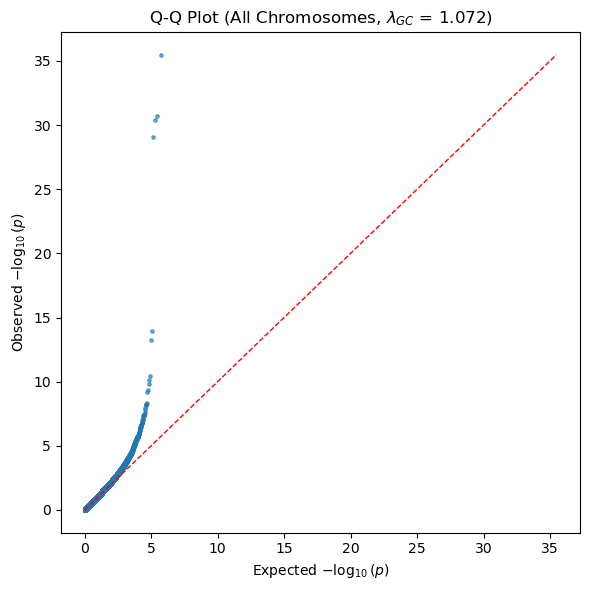

In [16]:
from scipy import stats

# Extract p-values from the full combined gwas_df instead of the single loop df
p = gwas_df[P].astype(float).values
p = p[(p > 0) & np.isfinite(p)]
p_sorted = np.sort(p)

# Define the expected uniform quantiles
n = len(p_sorted)
exp = (np.arange(1, n + 1) / (n + 1.0))

# Convert observed vs expected p-values to -log10 scale
obs_log = -np.log10(p_sorted)
exp_log = -np.log10(exp)

# Calculate the genomic inflation factor (lambda GC) from Chi-Square
chi_obs = stats.chi2.isf(p_sorted, df=1)
lambda_gc = np.nanmedian(chi_obs) / stats.chi2.ppf(0.5, 1) 

# Plot the Q-Q plot
plt.figure(figsize=(6, 6))
plt.scatter(exp_log, obs_log, s=6, alpha=0.6, color="tab:blue")

# Plot the diagonal line of expectation (y = x)
m = max(exp_log.max(), obs_log.max())
plt.plot([0, m], [0, m], linestyle="--", color="red", linewidth=1)

plt.xlabel(r"Expected $-\log_{10}(p)$")
plt.ylabel(r"Observed $-\log_{10}(p)$")
plt.title(f"Q-Q Plot (All Chromosomes, $\lambda_{{GC}}$ = {lambda_gc:.3f})")
plt.tight_layout()
plt.show()

We can infer that our data is trending away from the null-hypothesis line, and based on the lambda it has a 7.2% deviation from the line. Given the line is our baseline for our null hypothesis or no statistical significance, can see that there is some statistical significance in our dataset.

<div class="alert alert-block alert-warning">
    <h4>3.3.2 Explain λGC. What's your value for λGC? </h4>
</div>

λGC is the amount that our data deviates from the null hypothesis line. The higher this value, the higher the deviation, which would mean greater statistical significance.

<div class="alert alert-block alert-warning">
    <h4>3.3.3 Is there early upward deflection in your Q-Q plot? What does it indicate?</h4>
</div>

We do see an early upward deflection in our Q-Q plot, which can indicate confounding factors such as ancestry mismatches, batch effects, or relatedness. Typically using principle components addresses this.

<div class="alert alert-block alert-warning">
    <h2>Part 4 - Comparative analysis</h2>
    <h2> Total Points: 10+15+5 = 30</h2>
</div>

<div class="alert alert-block alert-warning">
    <h4>4.1 Run GWAS using a different tool. Explain why you chose to use this tool. </h4>
</div>

In [23]:
#Your code here

In [ ]:
!mkdir ~/scratch/gwas
!cd ~/scratch/gwas/

!unzip -q ~/biol650/Data2/GWAS/genotypes.zip -d .

In [ ]:
# removing backups

!cd ~/scratch/gwas/gentypes_100k/
!rm -f ~/scratch/gwas/gentypes_100k/*~

In [ ]:
%%bash

for chr in {1..22}; do echo c$chr; done > list.txt
plink2 --pmerge-list list.txt bfile --maf 0.01 --geno 0.02 \
       --make-bed --out all --threads 6 --memory 12000

Start time: Mon Nov  9 20:44:49 2026
257063 MiB RAM detected, ~160110 available; reserving 12000 MiB for main
workspace.
Using up to 6 compute threads.
--pmerge-list: 22 filesets specified.
--pmerge-list: 100000 samples and 1 phenotype present.
--pmerge-list: Merged .psam written to all.psam .
--pmerge-list: 22 .pvar files scanned.
Concatenation job detected.
Concatenating... 784256/784256 variants complete.
Results written to all.pgen + all.pvar .
100000 samples (54417 females, 45550 males, 33 ambiguous; 100000 founders)
loaded from all.psam.
784256 variants loaded from all.pvar.
Note: No phenotype data present.
Calculating allele frequencies... done.
--geno: 100844 variants removed due to missing genotype data.
98481 variants removed due to allele frequency threshold(s)
(--maf/--max-maf/--mac/--max-mac).
584931 variants remaining after main filters.
Writing all.fam ... done.
Writing all.bim ... done.
Writing all.bed ... done.
End time: Mon Nov  9 20:48:30 2026


In [7]:
%%bash
cd /storage/ice1/1/9/rshahrivar3/gwas/genotypes_100k

regenie --step 1 \
  --bed all \
  --phenoFile phe.tsv --phenoCol T2D \
  --covarFile covars.tsv --covarColList Age,PC{1:9} --catCovarList Sex \
  --bt --cc12 --bsize 1000 --lowmem --threads 6 \
  --out step1

Start time: Mon Nov  9 21:00:37 2026

              |===============================|
              |      REGENIE v4.1.3.1.gz      |
              |===============================|

Copyright (c) 2020-2024 Joelle Mbatchou, Andrey Ziyatdinov and Jonathan Marchini.
Distributed under the MIT License.
Compiled with Boost Iostream library.
Using Intel MKL with Eigen.

Log of output saved in file : step1.log

Options in effect:
  --step 1 \
  --bed all \
  --phenoFile phe.tsv \
  --phenoCol T2D \
  --covarFile covars.tsv \
  --covarColList Age,PC{1:9} \
  --catCovarList Sex \
  --bt \
  --cc12 \
  --bsize 1000 \
  --lowmem \
  --threads 6 \
  --out step1

Fitting null model
 * bim              : [all.bim] n_snps = 584931
 * fam              : [all.fam] n_samples = 100000
 * bed              : [all.bed]
 * phenotypes       : [phe.tsv] n_pheno = 1
   -dropping observations with missing values at any of the phenotypes
   -number of phenotyped individuals with no missing data = 99331
 * covaria

In [8]:
%%bash
cd /storage/ice1/1/9/rshahrivar3/gwas/genotypes_100k

regenie --step 2 \
  --bed all \
  --phenoFile phe.tsv --phenoCol T2D \
  --covarFile covars.tsv --covarColList Age,PC{1:9} --catCovarList Sex \
  --bt --cc12 --firth --approx \
  --pred step1_pred.list \
  --bsize 400 --threads 6 \
  --out step2

Start time: Mon Nov  9 21:39:23 2026

              |===============================|
              |      REGENIE v4.1.3.1.gz      |
              |===============================|

Copyright (c) 2020-2024 Joelle Mbatchou, Andrey Ziyatdinov and Jonathan Marchini.
Distributed under the MIT License.
Compiled with Boost Iostream library.
Using Intel MKL with Eigen.

Log of output saved in file : step2.log

Options in effect:
  --step 2 \
  --bed all \
  --phenoFile phe.tsv \
  --phenoCol T2D \
  --covarFile covars.tsv \
  --covarColList Age,PC{1:9} \
  --catCovarList Sex \
  --bt \
  --cc12 \
  --firth \
  --approx \
  --pred step1_pred.list \
  --bsize 400 \
  --threads 6 \
  --out step2

Association testing mode with fast multithreading using OpenMP
 * bim              : [all.bim] n_snps = 584931
 * fam              : [all.fam] n_samples = 100000
 * bed              : [all.bed]
 * phenotypes       : [phe.tsv] n_pheno = 1
   -dropping observations with missing values at any of the pheno

In [24]:
#Write your answer here

The reason why I chose REGENIE is that it's fast and memory-efficient for large data such as this UK biobank scale that we're working on. It also corrects for relatedness in it's 2 step model. https://rgcgithub.github.io/regenie/

<div class="alert alert-block alert-warning">
    <h4>4.2 Compare the parameters/outputs between plink and the tool you chose above.</h4>
</div>

In [25]:
#Write your answer here

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from glob import glob

REGENIE_FILE = "/storage/ice1/1/9/rshahrivar3/gwas/genotypes_100k/step2_T2D.regenie"
PLINK_DIR    = "gwas_results"

In [ ]:
rg = pd.read_csv(REGENIE_FILE, sep=" ")
rg["P"] = 10 ** -rg["LOG10P"]

pl = pd.concat([pd.read_csv(f, sep="\t") for f in glob(f"{PLINK_DIR}/c*.T2D.glm.logistic.hybrid")])
pl = pl[pl["TEST"] == "ADD"].dropna(subset=["P"])

# number of significant snps for each tool
print("plink", len(pl), (pl.P < 5e-8).sum())
print("REGENIE", len(rg), (rg.P < 5e-8).sum())

plink 584931 23
REGENIE 584931 25


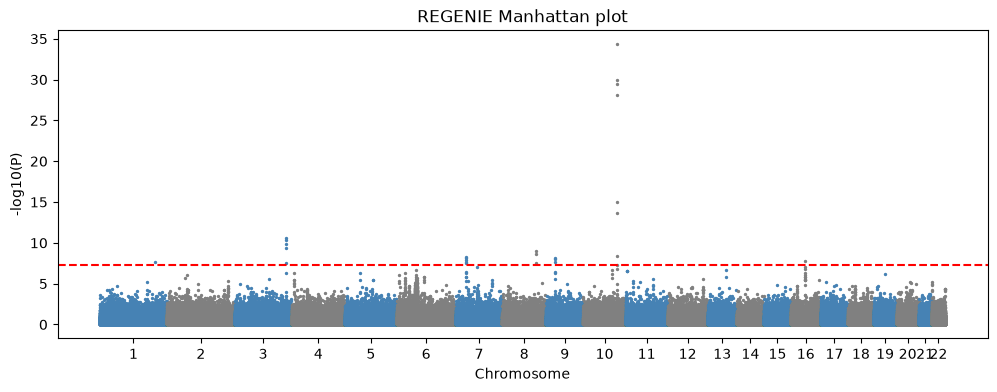

In [24]:
df = rg.sort_values(["CHROM", "GENPOS"]).reset_index(drop=True)
df["logp"] = -np.log10(df["P"])

plt.figure(figsize=(12, 4))
ticks = []
for c in range(1, 23):
    chr_df = df[df["CHROM"] == c]
    plt.scatter(chr_df.index, chr_df["logp"], s=2,
                color="steelblue" if c % 2 else "gray")
    ticks.append((chr_df.index[0] + chr_df.index[-1]) / 2)

plt.axhline(-np.log10(5e-8), color="red", ls="--")
plt.xticks(ticks, range(1, 23))
plt.xlabel("Chromosome"); plt.ylabel("-log10(P)")
plt.title("REGENIE Manhattan plot")
plt.show()

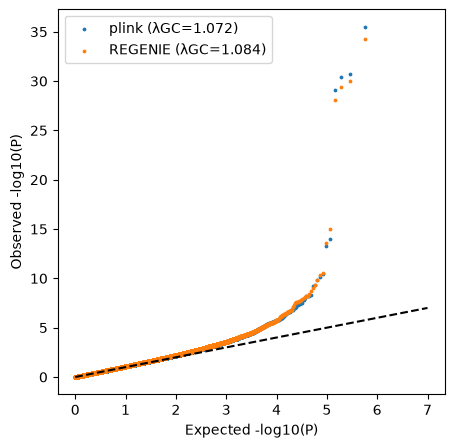

In [ ]:
from scipy.stats import chi2

plt.figure(figsize=(5, 5))
for name, p in [("plink", pl.P), ("REGENIE", rg.P)]:
    p = np.sort(p.values)
    expected = -np.log10(np.arange(1, len(p) + 1) / (len(p) + 1))
    lam = np.median(chi2.isf(p, 1)) / chi2.ppf(0.5, 1)
    plt.scatter(expected, -np.log10(p), s=3, label=f"{name} (λGC={lam:.3f})")
plt.plot([0, 7], [0, 7], "k--")
plt.xlabel("(E) -log10(P)"); plt.ylabel("(O) -log10(P)") # these are expected and observed p valz
plt.legend(); plt.show()

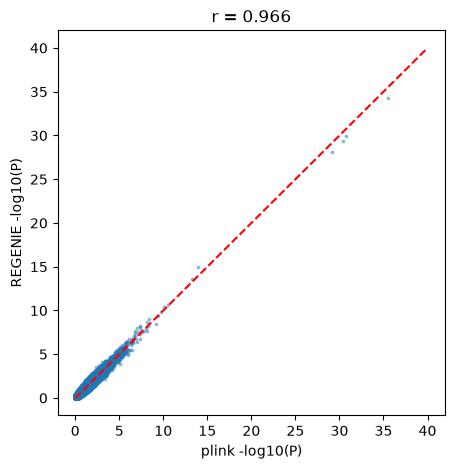

In [26]:
m = pl.merge(rg, on="ID")
plt.figure(figsize=(5, 5))
plt.scatter(-np.log10(m.P_x), m.LOG10P, s=3, alpha=0.4)
plt.plot([0, 40], [0, 40], "r--")
plt.xlabel("plink -log10(P)"); plt.ylabel("REGENIE -log10(P)")
plt.title(f"r = {np.corrcoef(-np.log10(m.P_x), m.LOG10P)[0,1]:.3f}")
plt.show()

- plink used --glm with firth-fallback, the covariates and the --maf/--geno filters. REGENIE used the same covariates and filters, plus --firth --approx and the Step 1 whole-genome model.
- plink gives OR and P. REGENIE gives BETA, which is the log of the odds ratio, and LOG10P.

Based on the plots you can see how similar these tools are, I used the same MAF>=0.01 and t he missingness of =< 0.02 with the same covariates. The manhattan plot is finding the same loci, and the values also correlate at r = 0.966. One small difference is that REGENIE detected 25 SNPs vs 23 for plink, which is I think because of the whole-genome model of REGENIE that plink lacks. The lambdaGC is also super close with REGENIE being a bit higher than plink (1.072 and 1.084). 

The strongest peak was also TCF7L2 on chr10, and both found them. We didn't do a proper runtime or memory/usage performance assessment, but it seems to me that REGENIE is faster and is aligned with plink results, even found 2 more SNPs.

<div class="alert alert-block alert-warning">
    <h4>4.3 On a scale of 1-10, how much did you rely on AI for the project?
<br>
(1 = not at all, 10 = heavily dependent) </h4>
</div>

In [28]:
#Write your answer here
#3